In [13]:
# %% [1] Imports & config
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             make_scorer, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

CSV_PATH = "/content/schoolliant_career_outcome_prediction.csv"  # <- edit this line only
SEED = 42
NUM = ["final_score", "project_score", "soft_skill_score",
       "attendance_pct", "mock_interview_score"]

plt.rcParams.update({"figure.dpi": 110,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

In [14]:
# %% [2] Load & clean (imputation happens inside the pipelines, not here)
raw = pd.read_csv(CSV_PATH)
df = raw.drop_duplicates().reset_index(drop=True)
df["y"] = (df["placed"] == "Yes").astype(int)
y = df["y"]

baseline_acc = y.value_counts(normalize=True).max()
print(f"Raw: {raw.shape} | after dedup: {df.shape}")
print(f"Missing mock_interview_score after dedup: {df['mock_interview_score'].isna().sum()}")
print(df["placed"].value_counts().to_string())
print(f"Majority-class baseline accuracy: {baseline_acc:.4f}")

Raw: (404, 10) | after dedup: (400, 11)
Missing mock_interview_score after dedup: 12
placed
Yes    238
No     162
Majority-class baseline accuracy: 0.5950


In [15]:
# %% [3] Pipeline builder & model set
def build(model, scale=True, num=NUM, cat=None):
    num_steps = [("imp", SimpleImputer(strategy="mean"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    transformers = [("num", Pipeline(num_steps), num)]
    if cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("clf", model)])


def get_models():
    return {
        "Baseline (majority)": build(DummyClassifier(strategy="most_frequent")),
        "Logistic Regression": build(LogisticRegression(max_iter=1000)),
        "SVM (RBF)": build(SVC(kernel="rbf")),
        "Random Forest": build(RandomForestClassifier(n_estimators=200, random_state=SEED), scale=False),
        "Gradient Boosting": build(GradientBoostingClassifier(random_state=SEED), scale=False),
    }


SCORING = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_placed": make_scorer(recall_score, pos_label=1),
    "recall_not_placed": make_scorer(recall_score, pos_label=0),
}


def run_cv(model, X, y, n_splits=5, n_repeats=20, scoring=SCORING):
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=SEED)
    return cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)


def fmt(a):
    return f"{np.mean(a) * 100:.2f}% ± {np.std(a) * 100:.2f}"

                          Accuracy          ROC-AUC Recall (placed) Recall (not placed)
Baseline (majority)  59.50% ± 0.61  0.5000 ± 0.0000  100.00% ± 0.00        0.00% ± 0.00
Logistic Regression  98.79% ± 1.14  0.9982 ± 0.0033   99.35% ± 1.02       97.96% ± 2.41
SVM (RBF)            98.87% ± 1.17  0.9994 ± 0.0011   99.37% ± 1.09       98.15% ± 2.32
Random Forest        98.65% ± 1.21  0.9992 ± 0.0014   98.97% ± 1.24       98.18% ± 2.32
Gradient Boosting    97.66% ± 2.12  0.9956 ± 0.0109   98.49% ± 1.65       96.45% ± 4.02


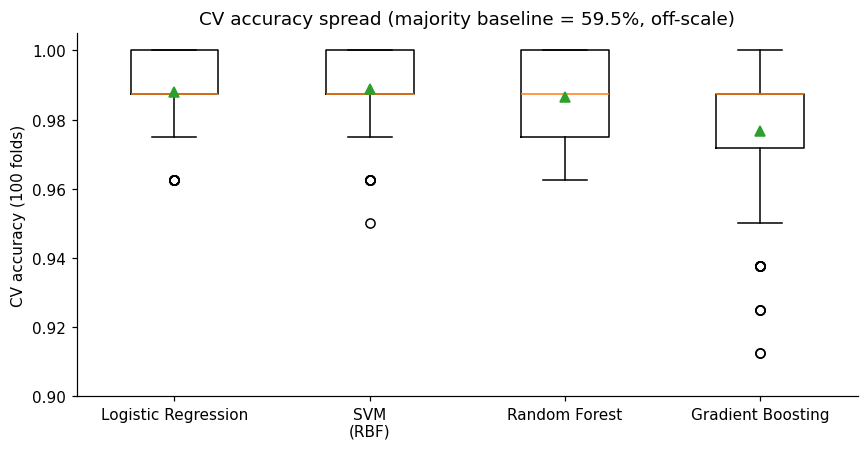

In [16]:
# %% [4] Repeated stratified CV (5 folds x 20 repeats)
X = df[NUM]
cv_results = {}
for name, m in get_models().items():
    cv_results[name] = run_cv(m, X, y)

table = pd.DataFrame({
    name: {
        "Accuracy": fmt(r["test_accuracy"]),
        "ROC-AUC": f"{np.mean(r['test_roc_auc']):.4f} ± {np.std(r['test_roc_auc']):.4f}",
        "Recall (placed)": fmt(r["test_recall_placed"]),
        "Recall (not placed)": fmt(r["test_recall_not_placed"]),
    } for name, r in cv_results.items()
}).T
print(table.to_string())

plot_names = [n for n in cv_results if not n.startswith("Baseline")]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.boxplot([cv_results[n]["test_accuracy"] for n in plot_names], showmeans=True)
ax.set_xticklabels([n.replace(" (", "\n(") for n in plot_names])
ax.set_ylim(0.90, 1.005)
ax.set_ylabel("CV accuracy (100 folds)")
ax.set_title(f"CV accuracy spread (majority baseline = {baseline_acc:.1%}, off-scale)")
plt.tight_layout()
plt.show()

Baseline (majority)    acc=0.6000  f1=0.7500  cm=[[0, 32], [0, 48]]
Logistic Regression    acc=0.9875  f1=0.9897  cm=[[31, 1], [0, 48]]
SVM (RBF)              acc=0.9875  f1=0.9897  cm=[[31, 1], [0, 48]]
Random Forest          acc=0.9750  f1=0.9792  cm=[[31, 1], [1, 47]]
Gradient Boosting      acc=0.9750  f1=0.9792  cm=[[31, 1], [1, 47]]
(Test set = 80 rows, so one student = 1.25 accuracy points)


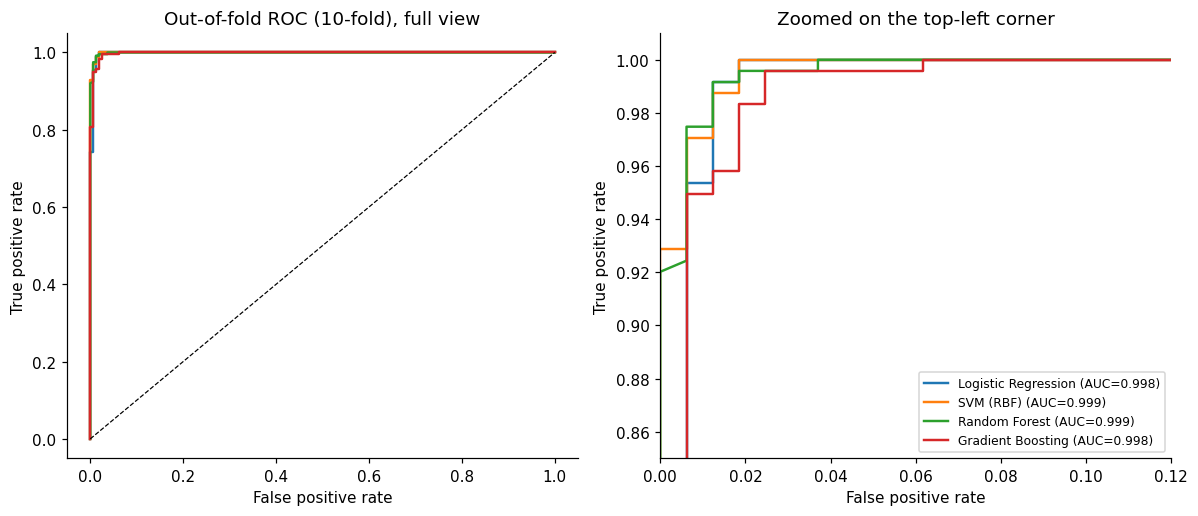

In [17]:
# %% [5] Hold-out test (same split as the original notebook) + ROC curves
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
for name, m in get_models().items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    print(f"{name:22s} acc={accuracy_score(y_te, pred):.4f}  "
          f"f1={f1_score(y_te, pred):.4f}  cm={confusion_matrix(y_te, pred).tolist()}")
print(f"(Test set = {len(y_te)} rows, so one student = {100 / len(y_te):.2f} accuracy points)")

cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(11, 4.8))
for name, m in get_models().items():
    if name.startswith("Baseline"):
        continue
    method = "predict_proba" if hasattr(m, "predict_proba") else "decision_function"
    s = cross_val_predict(m, X, y, cv=cv10, method=method)
    s = s[:, 1] if method == "predict_proba" else s
    fpr, tpr, _ = roc_curve(y, s)
    for ax in (ax_full, ax_zoom):
        ax.plot(fpr, tpr, lw=1.6, label=f"{name} (AUC={roc_auc_score(y, s):.3f})")
ax_full.plot([0, 1], [0, 1], "k--", lw=0.8)
ax_full.set_title("Out-of-fold ROC (10-fold), full view")
ax_zoom.set_xlim(0, 0.12)
ax_zoom.set_ylim(0.85, 1.01)
ax_zoom.set_title("Zoomed on the top-left corner")
for ax in (ax_full, ax_zoom):
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
ax_zoom.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

                      RF impurity (original method)  RF permutation (CV)  LR permutation (CV)  LR |std. coefficient|
final_score                                    11.1                 13.9                 27.8                   22.5
project_score                                  30.7                 40.2                 20.8                   20.7
soft_skill_score                               11.7                  4.3                  6.9                   15.6
attendance_pct                                 23.3                 26.3                 20.3                   19.1
mock_interview_score                           23.2                 15.3                 24.3                   22.1

LR standardized coefficients:
final_score             1.825
project_score           1.684
soft_skill_score        1.263
attendance_pct          1.548
mock_interview_score    1.797


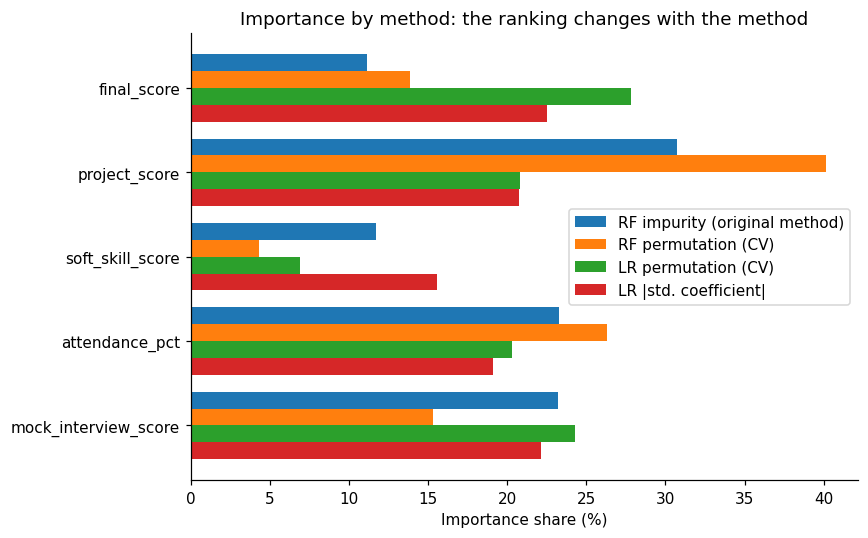


Single-feature ROC-AUC:
final_score             0.905
project_score           0.943
soft_skill_score        0.929
attendance_pct          0.922
mock_interview_score    0.943


In [18]:
# %% [6] Feature importance: RF impurity vs permutation vs LR coefficients
def cv_perm_importance(model, X, y, n_splits=5, n_repeats=10):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    out = []
    for tr, va in skf.split(X, y):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        r = permutation_importance(m, X.iloc[va], y.iloc[va], scoring="roc_auc",
                                   n_repeats=n_repeats, random_state=SEED)
        out.append(r.importances_mean)
    return np.mean(out, axis=0)


def share(v):
    v = np.clip(np.asarray(v, dtype=float), 0, None)
    return v / v.sum() * 100


rf_full = get_models()["Random Forest"].fit(X, y)
lr_full = get_models()["Logistic Regression"].fit(X, y)

imp = pd.DataFrame({
    "RF impurity (original method)": share(rf_full.named_steps["clf"].feature_importances_),
    "RF permutation (CV)": share(cv_perm_importance(get_models()["Random Forest"], X, y)),
    "LR permutation (CV)": share(cv_perm_importance(get_models()["Logistic Regression"], X, y)),
    "LR |std. coefficient|": share(np.abs(lr_full.named_steps["clf"].coef_[0])),
}, index=NUM)
print(imp.round(1).to_string())
print("\nLR standardized coefficients:")
print(pd.Series(lr_full.named_steps["clf"].coef_[0], index=NUM).round(3).to_string())

ax = imp.plot.barh(figsize=(8, 5), width=0.8)
ax.set_xlabel("Importance share (%)")
ax.set_title("Importance by method: the ranking changes with the method")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

single_auc = pd.Series({c: roc_auc_score(y, df[c].fillna(df[c].mean())) for c in NUM})
print("\nSingle-feature ROC-AUC:")
print(single_auc.round(3).to_string())

In [19]:
# %% [7] Does interview_readiness_score actually improve performance?
df["interview_readiness_score"] = (df["mock_interview_score"] + df["soft_skill_score"]) / 2
NUM_V2 = NUM + ["interview_readiness_score"]
X_all = df[NUM_V2 + ["course_name"]]

fe_rows = {}
for label, mdl, sc in [("Logistic Regression", LogisticRegression(max_iter=1000), True),
                       ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED), False)]:
    base = run_cv(build(clone(mdl), scale=sc, num=NUM), X_all, y)
    v2 = run_cv(build(clone(mdl), scale=sc, num=NUM_V2), X_all, y)
    fe_rows[label] = {
        "Acc (5 features)": fmt(base["test_accuracy"]),
        "Acc (+ readiness)": fmt(v2["test_accuracy"]),
        "AUC (5 features)": f"{np.mean(base['test_roc_auc']):.4f}",
        "AUC (+ readiness)": f"{np.mean(v2['test_roc_auc']):.4f}",
    }
print(pd.DataFrame(fe_rows).T.to_string())

                    Acc (5 features) Acc (+ readiness) AUC (5 features) AUC (+ readiness)
Logistic Regression    98.79% ± 1.14     98.83% ± 1.13           0.9982            0.9980
Random Forest          98.65% ± 1.21     98.69% ± 1.30           0.9992            0.9992


                             n  placed_rate
course_name                                
Deep Learning Fundamentals  47        0.468
Business Analytics          58        0.534
SQL Mastery                 61        0.574
Python for Beginners        47        0.574
Machine Learning            72        0.597
Power BI & Tableau          48        0.604
Data Science                67        0.761

Chi-square test, course vs placement: p = 0.0638


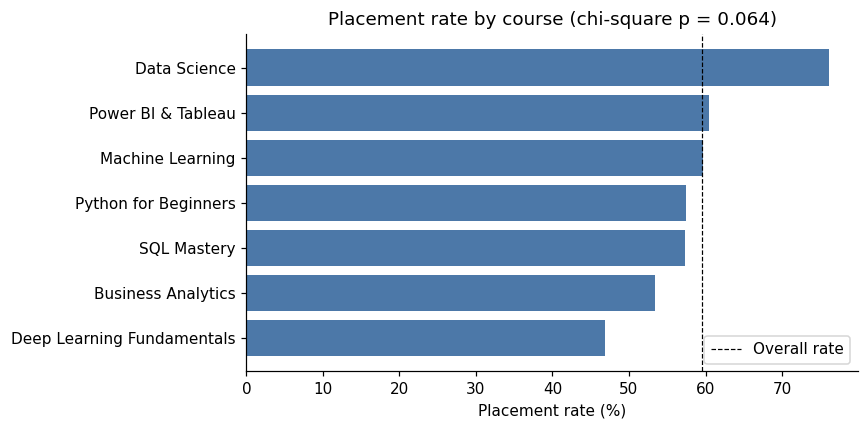

                    Acc (no course) Acc (+ course) AUC (no course) AUC (+ course)
Logistic Regression   98.79% ± 1.14  98.79% ± 1.14          0.9982         0.9982
Random Forest         98.65% ± 1.21  98.80% ± 1.24          0.9992         0.9993


In [20]:
# %% [8] Does course_name matter?
ct = pd.crosstab(df["course_name"], df["placed"])
chi2, p_course, _, _ = stats.chi2_contingency(ct)
rates = (ct["Yes"] / ct.sum(axis=1)).sort_values()
print(pd.DataFrame({"n": ct.sum(axis=1), "placed_rate": rates.round(3)}).loc[rates.index].to_string())
print(f"\nChi-square test, course vs placement: p = {p_course:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(rates.index, rates.values * 100, color="#4C78A8")
ax.axvline(y.mean() * 100, color="k", ls="--", lw=0.8, label="Overall rate")
ax.set_xlabel("Placement rate (%)")
ax.set_title(f"Placement rate by course (chi-square p = {p_course:.3f})")
ax.legend()
plt.tight_layout()
plt.show()

course_rows = {}
for label, mdl, sc in [("Logistic Regression", LogisticRegression(max_iter=1000), True),
                       ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED), False)]:
    without = run_cv(build(clone(mdl), scale=sc), X_all, y)
    with_c = run_cv(build(clone(mdl), scale=sc, cat=["course_name"]), X_all, y)
    course_rows[label] = {
        "Acc (no course)": fmt(without["test_accuracy"]),
        "Acc (+ course)": fmt(with_c["test_accuracy"]),
        "AUC (no course)": f"{np.mean(without['test_roc_auc']):.4f}",
        "AUC (+ course)": f"{np.mean(with_c['test_roc_auc']):.4f}",
    }
print(pd.DataFrame(course_rows).T.to_string())

salary_band
Entry     129
Mid        87
Senior     22
Majority-class baseline accuracy: 0.5420
Logistic Regression  acc=50.86% ± 4.82  macro-F1=0.270
Random Forest        acc=47.42% ± 5.95  macro-F1=0.300

Does any feature differ across salary bands?
                      ANOVA p-value
final_score                   0.631
project_score                 0.060
soft_skill_score              0.230
attendance_pct                0.315
mock_interview_score          0.933


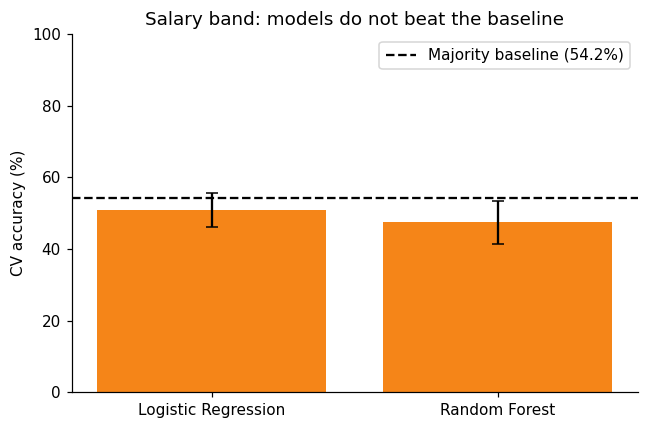

In [21]:
# %% [9] Salary band (placed students only) vs. majority baseline
placed = df[df["placed"] == "Yes"].reset_index(drop=True)
ys = placed["salary_band"]
sal_base = ys.value_counts(normalize=True).max()
print(ys.value_counts().to_string())
print(f"Majority-class baseline accuracy: {sal_base:.4f}")

sal_scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
sal_res = {}
for label, mdl, sc in [("Logistic Regression", LogisticRegression(max_iter=1000), True),
                       ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED), False)]:
    r = run_cv(build(mdl, scale=sc), placed[NUM], ys, scoring=sal_scoring)
    sal_res[label] = r
    print(f"{label:20s} acc={fmt(r['test_accuracy'])}  macro-F1={np.mean(r['test_macro_f1']):.3f}")

anova = pd.DataFrame({
    c: {"ANOVA p-value": stats.f_oneway(*[placed.loc[ys == b, c].dropna()
                                         for b in ["Entry", "Mid", "Senior"]]).pvalue}
    for c in NUM
}).T
print("\nDoes any feature differ across salary bands?")
print(anova.round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
names = list(sal_res)
ax.bar(names, [np.mean(sal_res[n]["test_accuracy"]) * 100 for n in names],
       yerr=[np.std(sal_res[n]["test_accuracy"]) * 100 for n in names],
       color="#F58518", capsize=4)
ax.axhline(sal_base * 100, color="k", ls="--", label=f"Majority baseline ({sal_base * 100:.1f}%)")
ax.set_ylabel("CV accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Salary band: models do not beat the baseline")
ax.legend()
plt.tight_layout()
plt.show()

Mean |corr| between scores: overall=0.519 | within placed=0.047 | within not placed=0.091


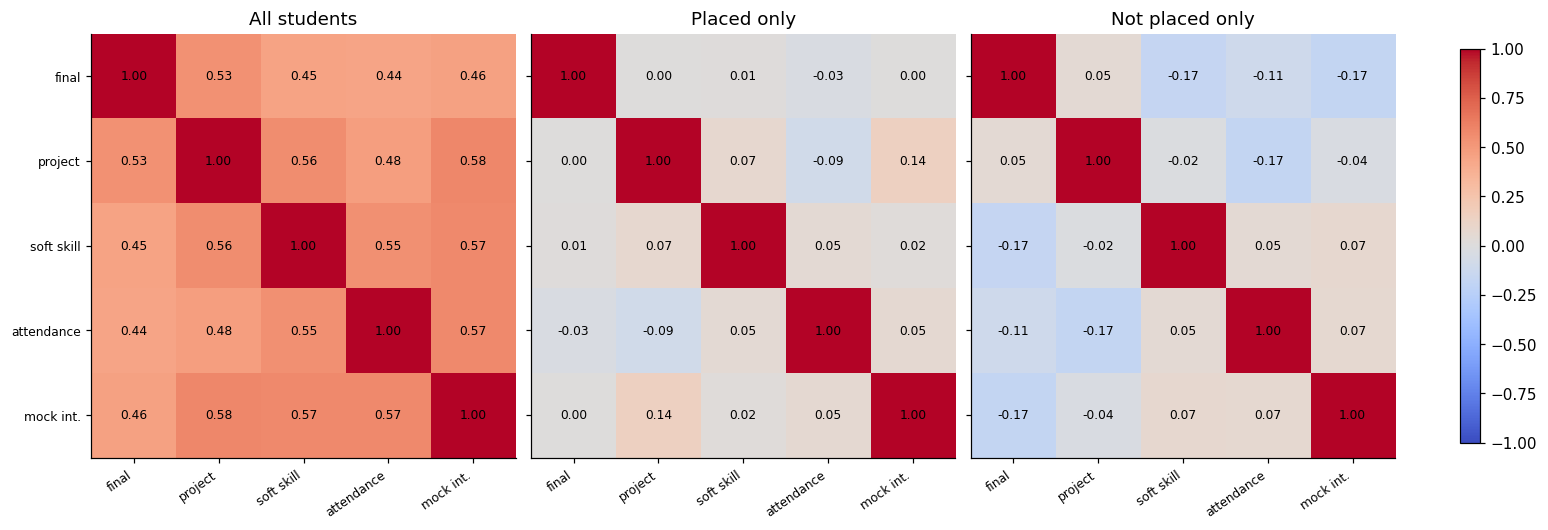


Value ranges by class (hard caps/floors are a synthetic-data signature):
                      min (placed)  max (placed)  min (not placed)  max (not placed)  # values == 100
final_score                   57.7         100.0              13.0              95.0                2
project_score                 58.4         100.0              23.6              95.0                4
soft_skill_score              45.9         100.0              15.1              95.0                2
attendance_pct                68.8         100.0              10.6             100.0               15
mock_interview_score          51.4         100.0              11.3              91.6                2


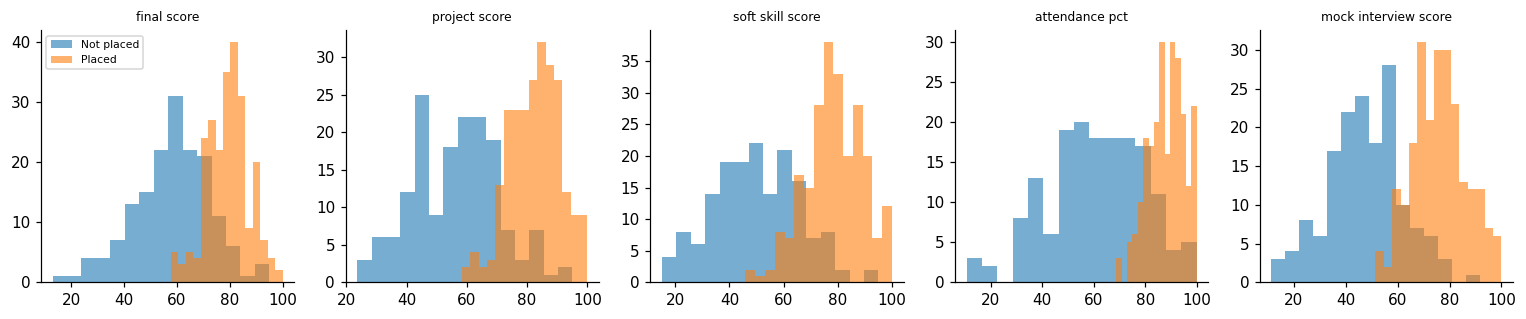

In [22]:
# %% [10] Synthetic-data diagnostics
def mean_abs_offdiag(c):
    return np.abs(c.values[np.triu_indices(len(c), 1)]).mean()


corr_all = df[NUM].corr()
corr_yes = df.loc[df["placed"] == "Yes", NUM].corr()
corr_no = df.loc[df["placed"] == "No", NUM].corr()
print(f"Mean |corr| between scores: overall={mean_abs_offdiag(corr_all):.3f} | "
      f"within placed={mean_abs_offdiag(corr_yes):.3f} | within not placed={mean_abs_offdiag(corr_no):.3f}")

short = ["final", "project", "soft skill", "attendance", "mock int."]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True, layout="constrained")
for ax, c, title in zip(axes, [corr_all, corr_yes, corr_no],
                        ["All students", "Placed only", "Not placed only"]):
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xticklabels(short, rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(short, fontsize=8)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{c.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

caps = pd.concat({
    "min (placed)": df[df["placed"] == "Yes"][NUM].min(),
    "max (placed)": df[df["placed"] == "Yes"][NUM].max(),
    "min (not placed)": df[df["placed"] == "No"][NUM].min(),
    "max (not placed)": df[df["placed"] == "No"][NUM].max(),
    "# values == 100": (df[NUM] == 100).sum(),
}, axis=1)
print("\nValue ranges by class (hard caps/floors are a synthetic-data signature):")
print(caps.round(1).to_string())

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, c in zip(axes, NUM):
    ax.hist(df.loc[df["placed"] == "No", c], bins=15, alpha=0.6, label="Not placed")
    ax.hist(df.loc[df["placed"] == "Yes", c], bins=15, alpha=0.6, label="Placed")
    ax.set_title(c.replace("_", " "), fontsize=8)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [23]:
# %% [11] Final pipeline (trained on all rows; performance numbers come from the CV above)
final_model = build(LogisticRegression(max_iter=1000))
final_model.fit(df[NUM], y)
joblib.dump(final_model, "placement_model.joblib")
loaded = joblib.load("placement_model.joblib")


def predict_placement(final_score, project_score, soft_skill_score,
                      attendance_pct, mock_interview_score):
    row = pd.DataFrame([{
        "final_score": final_score,
        "project_score": project_score,
        "soft_skill_score": soft_skill_score,
        "attendance_pct": attendance_pct,
        "mock_interview_score": mock_interview_score,
    }])
    return float(loaded.predict_proba(row)[0, 1])


print(f"Strong profile: {predict_placement(85, 85, 80, 90, 80):.1%}")
print(f"Weak profile:   {predict_placement(55, 50, 45, 55, 45):.1%}")
print(f"Borderline:     {predict_placement(70, 70, 65, 72, 65):.1%}")

Strong profile: 99.9%
Weak profile:   0.0%
Borderline:     41.4%


In [24]:
# %% [12] Key numbers for the report
lr, rf = cv_results["Logistic Regression"], cv_results["Random Forest"]
print("KEY NUMBERS")
print(f"Majority baseline accuracy (placement):  {baseline_acc:.3f}")
print(f"Logistic Regression CV accuracy / AUC:   {np.mean(lr['test_accuracy']):.4f} / {np.mean(lr['test_roc_auc']):.4f}")
print(f"Random Forest CV accuracy / AUC:         {np.mean(rf['test_accuracy']):.4f} / {np.mean(rf['test_roc_auc']):.4f}")
print(f"Recall on NOT placed (LR):               {np.mean(lr['test_recall_not_placed']):.4f}")
print(f"Salary majority baseline vs best model:  {sal_base:.3f} vs "
      f"{max(np.mean(r['test_accuracy']) for r in sal_res.values()):.3f}")
print(f"Course vs placement chi-square p:        {p_course:.4f}")
print(f"Mean |corr| within class (placed / not): {mean_abs_offdiag(corr_yes):.3f} / {mean_abs_offdiag(corr_no):.3f}")

KEY NUMBERS
Majority baseline accuracy (placement):  0.595
Logistic Regression CV accuracy / AUC:   0.9879 / 0.9982
Random Forest CV accuracy / AUC:         0.9865 / 0.9992
Recall on NOT placed (LR):               0.9796
Salary majority baseline vs best model:  0.542 vs 0.509
Course vs placement chi-square p:        0.0638
Mean |corr| within class (placed / not): 0.047 / 0.091


In [25]:
# %% [13] Hyperparameter tuning (nested CV, so tuned scores are not optimistic)
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "SVM (RBF)": {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    "Random Forest": {"clf__n_estimators": [100, 300],
                      "clf__max_depth": [None, 5, 10],
                      "clf__min_samples_split": [2, 5]},
    "Gradient Boosting": {"clf__n_estimators": [100, 200],
                          "clf__learning_rate": [0.05, 0.1],
                          "clf__max_depth": [2, 3]},
}

inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
models = get_models()

rows, best_params = {}, {}
for name, grid in grids.items():
    untuned = cross_validate(clone(models[name]), X, y, cv=outer, scoring="accuracy", n_jobs=-1)
    gs = GridSearchCV(clone(models[name]), grid, cv=inner, scoring="f1", n_jobs=-1)
    nested = cross_validate(gs, X, y, cv=outer, scoring="accuracy")
    gs.fit(X_tr, y_tr)
    best_params[name] = gs.best_params_
    pred = gs.predict(X_te)
    rows[name] = {
        "Untuned CV acc": fmt(untuned["test_score"]),
        "Tuned (nested) CV acc": fmt(nested["test_score"]),
        "Tuned hold-out acc": f"{accuracy_score(y_te, pred) * 100:.2f}%",
    }

print(pd.DataFrame(rows).T.to_string())
print("\nBest parameters (fitted on the 80% training split):")
for name, p in best_params.items():
    print(f"  {name}: {p}")

                    Untuned CV acc Tuned (nested) CV acc Tuned hold-out acc
Logistic Regression  98.88% ± 1.04         99.12% ± 1.26             98.75%
SVM (RBF)            99.00% ± 1.22         99.25% ± 1.15             98.75%
Random Forest        98.50% ± 1.22         98.62% ± 1.18             97.50%
Gradient Boosting    97.75% ± 2.22         98.62% ± 1.31             97.50%

Best parameters (fitted on the 80% training split):
  Logistic Regression: {'clf__C': 0.1}
  SVM (RBF): {'clf__C': 0.1, 'clf__gamma': 0.1}
  Random Forest: {'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
  Gradient Boosting: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200}
